# Notebook 63 | Where does the network lose SO(3) correction information?

**Frozen encoder, independently trained diagnostic decoders, and a signed-angle representation-path test.**

This is **not fine-tuning**: the complete original 6D model is loaded from a checkpoint, set to `eval()` and frozen. We generate rotation faults on *matched physical windows*, cache representations at multiple depths, and train **new small decoders only** on those cached features. The original head provides a baseline.

We answer four questions:

1. Can a new readout recover **unseen arbitrary-axis rotations on the same physical windows**?
2. Can the readout generalize to **new physical windows**?
3. Does recoverability degrade specifically **after particular Transformer layers or pooling**?
4. On a continuous signed SO(3) path, do different large rotations map to representations that are nearly indistinguishable?

**Critical interpretation safeguards:** Tokenized inputs and intermediate token sequences are summarized by deterministic, calibration-routed *temporal mean/std moments* to keep the probe tractable. Failure of a decoder on those summaries **does not** prove the complete token sequence lacks information. Likewise, a low pairwise-distance correlation alone does not prove a representation is unusable. The stronger indicator is a new decoder failing on *fixed training examples* or on *unseen directions*. All experiments use the existing left-multiplicative update convention and never use ground-truth residuals as decoder inputs.

## 1. Imports and local repository

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time
from contextlib import contextmanager
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run from the nn-obs-calib repository or a descendant directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.rotation_6d import matrix_to_rotation_6d, rotation_6d_to_matrix
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel, load_6d_pretrained_features
from obscalib.calibration.rotation_6d_update import apply_calibration_6d_update
from obscalib.training.rotation_6d_loss import Calibration6DLossWeights, calibration_6d_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())


Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126 | CUDA: True


## 2. Configuration and reproducible checkpoints

In [2]:
RUN_NAME_63 = 'kaist_pooled_calibration_6d_002.34_frozen_feature_probes'
RUN_DIR_63 = ROOT / 'runs' / RUN_NAME_63
RUN_DIR_63.mkdir(parents=True, exist_ok=True)

CHECKPOINTS_63 = {
    '002.27 original': ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt',
    '002.30 single-axis': ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz' / 'best.pt',
}
# A second checkpoint is informative but doubles full feature-extraction cost.
SELECTED_CHECKPOINTS_63 = ('002.27 original',)  # Optionally add '002.30 single-axis'.

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
SEED_63 = 63017
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0
REFINED_TAU_BY_SENSOR_S = {'imu': 0.0, 'lidar': -0.025, 'lidar_right': -0.035}
RANDOMIZE_TRUE_SENSOR_FRAMES = True
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
KAIST_TAU_IMU_S, KAIST_TAU_LIDAR_S, KAIST_TAU_LIDAR_RIGHT_S = 0.0, -0.025, -0.035

# Keep the held-out axes distinct, and do not select checkpoints using test sequences.
TRAIN_PHYSICAL_WINDOWS_63 = 16
VAL_PHYSICAL_WINDOWS_63 = 16
PHYSICAL_BATCH_SIZE_63 = 4
TRAIN_AXIS_DIRECTIONS_63 = 4
HELDOUT_AXIS_DIRECTIONS_63 = 3
TRAIN_ANGLES_63 = (0., 15., 30., 60., 90., 120., 150., 175., 179.)
EVAL_ANGLES_63 = TRAIN_ANGLES_63  # Same angles but axes never observed during probe training.
TEMPORAL_BINS_63 = 2
CAPTURE_LAYERS_63 = (0, 2, 5, 8, 11)
RUN_FEATURE_EXTRACTION_63 = True
RUN_DECODER_TRAINING_63 = True
RUN_SIGNED_PATH_63 = True
PATH_CHECKPOINT_63 = SELECTED_CHECKPOINTS_63[0]
PATH_FAULT_KEY_63 = 'lidar'
PATH_AXES_63 = ('X', 'U1')
PATH_NUM_ANGLES_63 = 37

# Separate decoders for each sensor avoid confounding encoder information with task-gradient sharing.
DECODER_PER_KEY_63 = True
DECODER_EPOCHS_63 = 140
DECODER_LR_63 = 1e-3
DECODER_WEIGHT_DECAY_63 = 1e-5
DECODER_BATCH_SIZE_63 = 128
DECODER_HIDDEN_63 = (256, 128)
DECODER_CHORDAL_WEIGHT_63 = 0.1
DECODER_REPORT_EVERY_63 = 25
SHOW_PLOTS = True

assert all(CHECKPOINTS_63[name].is_file() for name in SELECTED_CHECKPOINTS_63), 'One or more selected checkpoints are missing.'
assert PATH_CHECKPOINT_63 in SELECTED_CHECKPOINTS_63
assert PATH_FAULT_KEY_63 in CALIBRATION_KEYS
assert all(0 <= i < NUM_TRANSFORMER_LAYERS for i in CAPTURE_LAYERS_63)
random.seed(SEED_63); np.random.seed(SEED_63); torch.manual_seed(SEED_63)
if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(SEED_63)
print('Device:', DEVICE, '| checkpoints:', SELECTED_CHECKPOINTS_63, '| output:', RUN_DIR_63)


Device: cuda | checkpoints: ('002.27 original',) | output: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.34_frozen_feature_probes


## 3. KAIST physical windows and target calibration

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)


print('Train:', TRAIN_NAMES, '| Val:', VAL_NAMES, '| Test (not opened):', TEST_NAMES)


Train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16'] | Val: ['Urban26', 'Urban28'] | Test (not opened): ['Urban38', 'Urban39']


In [4]:
all_specs_63 = build_kaist_sequence_specs(sequence_names=TRAIN_NAMES + VAL_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs_63:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name_63 = {spec.name: spec for spec in all_specs_63}
train_dataset_63 = KAISTCalibrationDataset([spec_by_name_63[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset_63 = KAISTCalibrationDataset([spec_by_name_63[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
for name, dataset in [('train', train_dataset_63), ('validation', val_dataset_63)]:
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS
    print(name, 'windows:', len(dataset))


train windows: 2006
validation windows: 418


## 4. Frozen model, existing augmentation, and invariant checks

In [5]:
true_calibration_config_63 = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(enabled=RANDOMIZE_TRUE_SENSOR_FRAMES, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=0.0, rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD)),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter_63 = AugmentationPipeline(true_calibration_config_63)
model_config_63 = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
geometry_processor_63 = GeometryProcessor()
tokenizer_63 = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)

def generator_63(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def rotation_error_deg_63(R1, R2):
    R = R1 @ R2.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1]-R[..., 1, 2], R[..., 0, 2]-R[..., 2, 0], R[..., 1, 0]-R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1)-1.)))

def perturb_prior_63(states, key, angle_rad, direction):
    xi = torch.as_tensor(direction, device=DEVICE, dtype=DTYPE).view(1,3) * float(angle_rad)
    n = states[key].transform.shape[0]
    updated = dict(states)
    T = states[key].transform.clone()
    T[:, :3, :3] = so3_exp(xi.expand(n,-1)) @ T[:, :3, :3]
    updated[key] = replace(states[key], transform=T)
    return updated

def with_prior_63(window, prior):
    return WindowBatch(streams=dict(window.streams), current_calibration=prior, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)

def load_frozen_model_63(checkpoint_name):
    candidate = PooledCalibration6DModel(model_config_63).to(device=DEVICE, dtype=DTYPE)
    load_training_checkpoint(CHECKPOINTS_63[checkpoint_name], model=candidate, map_location=DEVICE, restore_rng_state=False)
    candidate.eval().requires_grad_(False)
    assert not any(p.requires_grad for p in candidate.parameters())
    return candidate

@torch.inference_mode()
def make_physical_groups_63(dataset, n_windows, seed):
    indices = np.unique(np.linspace(0, len(dataset)-1, min(n_windows,len(dataset))).round().astype(int))
    groups = []
    for group_id, offset in enumerate(range(0, len(indices), PHYSICAL_BATCH_SIZE_63)):
        chosen = indices[offset:offset+PHYSICAL_BATCH_SIZE_63]
        base = window_batch_to(collate_windows([dataset[int(index)] for index in chosen]), DEVICE, dtype=DTYPE)
        physical = physical_augmenter_63(base, generator=generator_63(seed+1009*group_id)).augmented_window
        assert physical.targets is not None
        groups.append((chosen.copy(), physical))
    return groups

train_physical_groups_63 = make_physical_groups_63(train_dataset_63, TRAIN_PHYSICAL_WINDOWS_63, SEED_63+1)
val_physical_groups_63 = make_physical_groups_63(val_dataset_63, VAL_PHYSICAL_WINDOWS_63, SEED_63+2)
print('Fixed physical windows:', sum(len(i) for i,_ in train_physical_groups_63), 'train /', sum(len(i) for i,_ in val_physical_groups_63), 'validation')


Fixed physical windows: 16 train / 16 validation


## 5. Feature extraction at several Transformer depths

**Feature protocol.** For each calibration key we split its masked chronological measurement tokens into two equal-count bins, compute per-bin means and standard deviations, and concatenate features from **all three sensors**. Each intermediate Transformer level uses the same fixed readout. The original model pooler and shared MLP are captured separately at their actual calibration-key outputs. Data from other sensors is included at early levels so alignment is possible. We never provide the GT rotation, fault axis, or fault angle to a decoder.

Hooks locate actual PyTorch Transformer layers by module type. If your local encoder implementation uses different layer classes, this cell fails with a clear message instead of silently capturing the wrong tensors.

In [6]:
def routed_temporal_moments_63(sequence, tokens, n_bins=TEMPORAL_BINS_63):
    """Fixed chronological per-key mean/std. No learned parameters or GT information."""
    if isinstance(sequence, (tuple, list)):
        sequence = sequence[0]
    B, N = tokens.x.shape[:2]
    if sequence.ndim != 3:
        raise ValueError(f'Expected [B,N,D] sequence, got {tuple(sequence.shape)}')
    if sequence.shape[0] != B and sequence.shape[1] == B:
        sequence = sequence.transpose(0, 1)
    if sequence.shape[0] != B or sequence.shape[1] < N:
        raise ValueError(f'Encoder layer has unexpected layout {tuple(sequence.shape)} for B={B}, N={N}')
    sequence = sequence[:, :N].float()
    result = []
    for b in range(B):
        per_sensor = []
        for key_id in range(len(CALIBRATION_KEYS)):
            valid = tokens.token_mask[b].bool() & (tokens.calibration_ids[b] == key_id)
            values = sequence[b, valid]
            sensor_moments = []
            for part in torch.tensor_split(values, n_bins, dim=0):
                if part.shape[0]:
                    mean = part.mean(dim=0)
                    std = part.std(dim=0, unbiased=False)
                else:
                    mean = torch.zeros(sequence.shape[-1],device=sequence.device)
                    std = torch.zeros_like(mean)
                sensor_moments.extend((mean, std))
            per_sensor.extend(sensor_moments)
        result.append(torch.cat(per_sensor))
    return torch.stack(result)

@contextmanager
def capture_model_levels_63(model):
    captures = {}
    layers = [(name, module) for name,module in model.transformer_encoder.named_modules() if isinstance(module, nn.TransformerEncoderLayer)]
    if len(layers) != NUM_TRANSFORMER_LAYERS:
        raise RuntimeError(f'Expected {NUM_TRANSFORMER_LAYERS} nn.TransformerEncoderLayer modules, found {len(layers)}: {[n for n,_ in layers]}. Inspect model.transformer_encoder.named_modules() and adapt hook type, do not guess layer ordering.')
    handles = []
    def hook_layer(index):
        def hook(_module, _inputs, output):
            captures[f'layer_{index:02d}'] = output.detach() if isinstance(output,torch.Tensor) else output[0].detach()
        return hook
    for index in CAPTURE_LAYERS_63:
        handles.append(layers[index][1].register_forward_hook(hook_layer(index)))
    def hook_final(_module, _inputs, output):
        captures['transformer_final'] = output.sequence.detach()
    def hook_pool(_module, _inputs, output):
        captures['pooler'] = output.detach()
    handles.append(model.transformer_encoder.register_forward_hook(hook_final))
    handles.append(model.pooler.register_forward_hook(hook_pool))
    try:
        yield captures
    finally:
        for handle in handles: handle.remove()
        captures.clear()

def extract_features_63(model, window, captures):
    captures.clear()
    canonical = geometry_processor_63(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer_63(canonical, calibration_keys=CALIBRATION_KEYS)

    # Disable the optimized NestedTensor path while capturing intermediate
    # Transformer features. Restore the original setting afterward.
    previous_fastpath = torch.backends.mha.get_fastpath_enabled()

    try:
        torch.backends.mha.set_fastpath_enabled(False)
        with torch.inference_mode():
            out = model(tokens)
    finally:
        torch.backends.mha.set_fastpath_enabled(previous_fastpath)

    features = {'tokenized': routed_temporal_moments_63(tokens.x,tokens)}
    for index in CAPTURE_LAYERS_63:
        name = f'layer_{index:02d}'
        if name not in captures:
            raise RuntimeError(f'{name} not captured, verify local Transformer architecture.')
        features[name] = routed_temporal_moments_63(captures[name],tokens)
    features['transformer_final'] = routed_temporal_moments_63(captures['transformer_final'],tokens)
    pooled = captures['pooler']
    if pooled.ndim != 3 or tuple(pooled.shape[:2]) != (tokens.x.shape[0],len(CALIBRATION_KEYS)):
        raise ValueError(f'Unexpected pooler output shape {tuple(pooled.shape)}')
    for key_index,key in enumerate(CALIBRATION_KEYS):
        features[f'pooler/{key}'] = pooled[:,key_index].float()
        features[f'shared_mlp/{key}'] = out.shared_features[:,key_index].float()
        features[f'original_6d/{key}'] = out.predictions[key].rotation_6d.float()
    return {key:value.cpu().numpy().copy() for key,value in features.items()}

# The stages are the same for all experiments. Separate pooler/shared features are routed by fault key.
GLOBAL_LEVELS_63 = ['tokenized'] + [f'layer_{i:02d}' for i in CAPTURE_LAYERS_63] + ['transformer_final']
LEVELS_63 = GLOBAL_LEVELS_63 + ['pooler', 'shared_mlp']
print('Representation stages:', LEVELS_63)


Representation stages: ['tokenized', 'layer_00', 'layer_02', 'layer_05', 'layer_08', 'layer_11', 'transformer_final', 'pooler', 'shared_mlp']


## 6. Train, same-window held-out axes, and unseen-window held-out axes

In [7]:
def sample_axes_63(n, seed):
    axes = np.random.default_rng(int(seed)).normal(size=(n,3))
    return axes/np.linalg.norm(axes,axis=1,keepdims=True)

TRAIN_AXES_63 = sample_axes_63(TRAIN_AXIS_DIRECTIONS_63,SEED_63+101)
HELDOUT_AXES_63 = sample_axes_63(HELDOUT_AXIS_DIRECTIONS_63,SEED_63+202)
assert min(np.linalg.norm(a-b) for a in TRAIN_AXES_63 for b in HELDOUT_AXES_63)>1e-5
print('Train axes:',np.round(TRAIN_AXES_63,2),'\nHeld-out axes:',np.round(HELDOUT_AXES_63,2))

def row_feature_63(features,level,key):
    return features[level] if level in GLOBAL_LEVELS_63 else features[f'{level}/{key}']

@torch.inference_mode()
def build_feature_bank_63(model, physical_groups, axes, angles, split):
    """One faulted sensor per case; physical data and true frame remain fixed within a group."""
    banks = {level:[] for level in LEVELS_63}
    rows=[]; target_R=[]; original_6d=[]
    with capture_model_levels_63(model) as captures:
        for group_number,(indices,physical) in enumerate(physical_groups):
            for fault_key in CALIBRATION_KEYS:
                for axis_id,direction in enumerate(axes):
                    for sign in (-1,1):
                        for angle in angles:
                            if angle == 0 and (axis_id!=0 or sign!=1):
                                continue
                            prior = perturb_prior_63(physical.current_calibration,fault_key,float(np.deg2rad(angle)*sign),direction)
                            window = with_prior_63(physical,prior)
                            actual_gt = physical.targets[fault_key].next_transform[:,:3,:3]
                            correction = actual_gt @ prior[fault_key].transform[:,:3,:3].transpose(-1,-2)
                            measured = rotation_error_deg_63(prior[fault_key].transform[:,:3,:3],actual_gt)
                            if not torch.allclose(measured,torch.full_like(measured,float(angle)),atol=0.1,rtol=0):
                                raise AssertionError(f'Rotation convention mismatch: {split} {fault_key} {angle}')
                            batch_features = extract_features_63(model,window,captures)
                            for level in LEVELS_63:
                                banks[level].append(row_feature_63(batch_features,level,fault_key))
                            original_6d.append(batch_features[f'original_6d/{fault_key}'])
                            target_R.append(correction.cpu().numpy().copy())
                            for sample_index in indices:
                                rows.append(dict(split=split, physical_index=int(sample_index), fault_key=fault_key, angle_deg=float(angle), sign=int(sign if angle else 0), axis_id=int(axis_id)))
            print(f'{split}: group {group_number+1}/{len(physical_groups)} complete',flush=True)
    X = {level: np.concatenate(items,axis=0).astype('float32') for level,items in banks.items()}
    result = dict(X=X, meta=pd.DataFrame(rows), R=np.concatenate(target_R,axis=0).astype('float32'), original_6d=np.concatenate(original_6d,axis=0).astype('float32'))
    assert len(result['meta']) == len(result['R']) == len(result['original_6d'])
    for level,arr in X.items():
        assert arr.shape[0]==len(result['meta']) and np.isfinite(arr).all(),f'{level} invalid shape/nan'
    return result

FEATURE_BANKS_63 = {}
if RUN_FEATURE_EXTRACTION_63:
    for checkpoint in SELECTED_CHECKPOINTS_63:
        print('Extracting',checkpoint,flush=True)
        frozen = load_frozen_model_63(checkpoint)
        FEATURE_BANKS_63[checkpoint] = {
            'train': build_feature_bank_63(frozen,train_physical_groups_63,TRAIN_AXES_63,TRAIN_ANGLES_63,'train'),
            'train_new_axes': build_feature_bank_63(frozen,train_physical_groups_63,HELDOUT_AXES_63,EVAL_ANGLES_63,'train_new_axes'),
            'val_new_axes': build_feature_bank_63(frozen,val_physical_groups_63,HELDOUT_AXES_63,EVAL_ANGLES_63,'val_new_axes'),
        }
        del frozen
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    print('Extracted cached representations for:',tuple(FEATURE_BANKS_63))


Train axes: [[-0.4  -0.33  0.86]
 [-0.38  0.92 -0.14]
 [ 0.41  0.84 -0.36]
 [ 0.14  0.55  0.82]] 
Held-out axes: [[-0.06 -0.77  0.64]
 [ 0.93 -0.35  0.09]
 [ 0.75  0.64 -0.18]]
Extracting 002.27 original


train: group 1/4 complete
train: group 2/4 complete
train: group 3/4 complete
train: group 4/4 complete
train_new_axes: group 1/4 complete
train_new_axes: group 2/4 complete
train_new_axes: group 3/4 complete
train_new_axes: group 4/4 complete
val_new_axes: group 1/4 complete
val_new_axes: group 2/4 complete
val_new_axes: group 3/4 complete
val_new_axes: group 4/4 complete
Extracted cached representations for: ('002.27 original',)


## 7. Frozen-feature readout training (no backbone updates)

**Training objective:** regression to the *exact* left SO(3) correction in 6D, with a small chordal term on the decoded rotation. Each level uses the **same two-hidden-layer decoder**. We standardize with training features only and train separate decoders by faulted sensor. No fault angle or axis labels enter the decoder. The early-stop selector is unseen axes on **training physical windows**; the independent validation physical windows are never used for selection.

Report: training residual, held-out axes on the same physical windows, and held-out axes on unseen validation physical windows. For each, show final geodesic error, predicted correction magnitude, and signed axis cosine. A low training MSE with a large SO(3) residual is explicitly detectable.

In [8]:
class FrozenFeatureDecoder63(nn.Module):
    def __init__(self, d_in, d_hidden=DECODER_HIDDEN_63):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(d_in,d_hidden[0]),nn.GELU(),nn.Linear(d_hidden[0],d_hidden[1]),nn.GELU(),nn.Linear(d_hidden[1],6))
    def forward(self,x): return self.layers(x)

def prepare_level_data_63(banks,level,key):
    prepared={}
    # Key filtering is essential; otherwise fault-key identity would be unavailable to a shared decoder.
    for name,bank in banks.items():
        m=(bank['meta'].fault_key.to_numpy()==key)
        prepared[name] = dict(X=bank['X'][level][m], R=bank['R'][m], meta=bank['meta'][m].reset_index(drop=True), original_6d=bank['original_6d'][m])
    train_x=prepared['train']['X']
    mean=train_x.mean(axis=0,keepdims=True)
    scale=train_x.std(axis=0,keepdims=True)
    # Exact-zero / nearly constant dims convey no useful variation; avoid unstable gains.
    scale=np.maximum(scale,1e-3)
    for split,data in prepared.items():
        data['X']=np.clip((data['X']-mean)/scale,-15,15).astype('float32')
    return prepared

def rotation_axis_cosine_63(R_pred,R_true):
    def axis(R): return torch.stack((R[...,2,1]-R[...,1,2],R[...,0,2]-R[...,2,0],R[...,1,0]-R[...,0,1]),dim=-1)
    x,y=axis(R_pred),axis(R_true)
    nx,ny=x.norm(dim=-1),y.norm(dim=-1)
    cs=(x*y).sum(-1)/(nx*ny).clamp_min(1e-10)
    return torch.where((nx>1e-4)&(ny>1e-4),cs.clamp(-1,1),torch.full_like(cs,float('nan')))

@torch.inference_mode()
def probe_decoder_63(decoder, data, checkpoint, level, key, split):
    decoder.eval()
    X=torch.tensor(data['X'],device=DEVICE)
    R_true=torch.tensor(data['R'],device=DEVICE)
    predicted=torch.cat([decoder(x) for x in X.split(DECODER_BATCH_SIZE_63)],dim=0)
    R_pred=rotation_6d_to_matrix(predicted)
    error=rotation_error_deg_63(R_pred,R_true)
    eye=torch.eye(3,device=DEVICE).expand_as(R_pred)
    magnitude=rotation_error_deg_63(R_pred,eye)
    cosine=rotation_axis_cosine_63(R_pred,R_true)
    base_r6=torch.tensor(data['original_6d'],device=DEVICE)
    base_R=rotation_6d_to_matrix(base_r6)
    base_error=rotation_error_deg_63(base_R,R_true)
    meta=data['meta'].copy()
    meta['checkpoint']=checkpoint; meta['level']=level; meta['split']=split
    meta['decoder_error_deg']=error.cpu().numpy()
    meta['original_head_error_deg']=base_error.cpu().numpy()
    meta['decoder_magnitude_deg']=magnitude.cpu().numpy()
    meta['axis_cosine']=cosine.cpu().numpy()
    meta['gt_magnitude_deg']=rotation_error_deg_63(R_true,eye).cpu().numpy()
    return meta

def train_level_probe_63(checkpoint,level,key,banks):
    data=prepare_level_data_63(banks,level,key)
    x=torch.tensor(data['train']['X'],device=DEVICE)
    R=torch.tensor(data['train']['R'],device=DEVICE)
    target=matrix_to_rotation_6d(R)
    model=FrozenFeatureDecoder63(x.shape[1]).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=DECODER_LR_63,weight_decay=DECODER_WEIGHT_DECAY_63)
    generator=torch.Generator().manual_seed(SEED_63 + CALIBRATION_KEYS.index(key)*111 + LEVELS_63.index(level)*13)
    best_state=None; best_metric=float('inf'); best_epoch=-1
    hist=[]
    # Precomputed representations are detached by construction: backbone NEVER sees a gradient.
    for epoch in range(1,DECODER_EPOCHS_63+1):
        model.train()
        order=torch.randperm(len(x),generator=generator).to(DEVICE)
        running=[]
        for idx in order.split(DECODER_BATCH_SIZE_63):
            pred=model(x[idx]); R_pred=rotation_6d_to_matrix(pred)
            mse=(pred-target[idx]).square().mean()
            chord=0.5*(R_pred-R[idx]).square().sum(dim=(-1,-2)).mean()
            loss=mse+DECODER_CHORDAL_WEIGHT_63*chord
            optimizer.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),5.0); optimizer.step()
            running.append(float(loss.detach()))
        # Selection by heldout axes on SAME physical windows, not by val physical windows.
        if epoch==1 or epoch%5==0 or epoch==DECODER_EPOCHS_63:
            held=probe_decoder_63(model,data['train_new_axes'],checkpoint,level,key,'train_new_axes')
            metric=float(held.decoder_error_deg.mean())
            hist.append(dict(checkpoint=checkpoint,level=level,key=key,epoch=epoch,train_loss=np.mean(running),heldout_axes_deg=metric))
            if metric<best_metric:
                best_metric=metric;best_epoch=epoch
                best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    outputs=[probe_decoder_63(model,data[split],checkpoint,level,key,split) for split in data]
    return outputs,pd.DataFrame(hist),dict(checkpoint=checkpoint,level=level,key=key,chosen_epoch=best_epoch,heldout_axes_deg=best_metric)

DECODER_CASES_63=[];DECODER_HISTORY_63=[];DECODER_SUMMARY_63=[]
if RUN_DECODER_TRAINING_63:
    if not FEATURE_BANKS_63:
        raise RuntimeError('Run feature extraction first: FEATURE_BANKS_63 is empty.')
    for checkpoint,banks in FEATURE_BANKS_63.items():
        for level in LEVELS_63:
            for key in CALIBRATION_KEYS:
                results,hist,summary=train_level_probe_63(checkpoint,level,key,banks)
                DECODER_CASES_63.extend(results);DECODER_HISTORY_63.append(hist);DECODER_SUMMARY_63.append(summary)
                val=[r for r in results if r.split.iloc[0]=='val_new_axes'][0]
                print(f'{checkpoint:20s} {level:18s} {key:11s} | train-axes={summary["heldout_axes_deg"]:6.1f}° | unseen-physical={val.decoder_error_deg.mean():6.1f}°',flush=True)
    decoder_cases_df_63=pd.concat(DECODER_CASES_63,ignore_index=True)
    decoder_history_df_63=pd.concat(DECODER_HISTORY_63,ignore_index=True)
    decoder_summary_df_63=pd.DataFrame(DECODER_SUMMARY_63)
    decoder_cases_df_63.to_csv(RUN_DIR_63/'decoder_case_metrics.csv',index=False)
    decoder_history_df_63.to_csv(RUN_DIR_63/'decoder_training_history.csv',index=False)
    decoder_summary_df_63.to_csv(RUN_DIR_63/'decoder_selection.csv',index=False)
    display(decoder_summary_df_63)


002.27 original      tokenized          imu         | train-axes=  69.7° | unseen-physical=  74.9°
002.27 original      tokenized          lidar       | train-axes=  73.7° | unseen-physical=  92.1°
002.27 original      tokenized          lidar_right | train-axes=  73.9° | unseen-physical=  88.0°
002.27 original      layer_00           imu         | train-axes=  70.2° | unseen-physical=  68.8°
002.27 original      layer_00           lidar       | train-axes=  85.1° | unseen-physical=  86.4°
002.27 original      layer_00           lidar_right | train-axes=  80.9° | unseen-physical=  85.3°
002.27 original      layer_02           imu         | train-axes=  67.0° | unseen-physical=  66.9°
002.27 original      layer_02           lidar       | train-axes=  82.2° | unseen-physical=  91.6°
002.27 original      layer_02           lidar_right | train-axes=  80.0° | unseen-physical=  87.2°
002.27 original      layer_05           imu         | train-axes=  63.0° | unseen-physical=  63.9°
002.27 ori

,checkpoint,level,key,chosen_epoch,heldout_axes_deg
0,002.27 original,tokenized,imu,45,69.674881
1,002.27 original,tokenized,lidar,110,73.746620
2,002.27 original,tokenized,lidar_right,140,73.898773
3,002.27 original,layer_00,imu,1,70.210297
4,002.27 original,layer_00,lidar,85,85.058266
5,002.27 original,layer_00,lidar_right,130,80.889481
6,002.27 original,layer_02,imu,10,66.984734
7,002.27 original,layer_02,lidar,60,82.200134
8,002.27 original,layer_02,lidar_right,110,80.008362
9,002.27 original,layer_05,imu,115,62.985340


## 8. Per-angle SO(3) performance and where decodability disappears

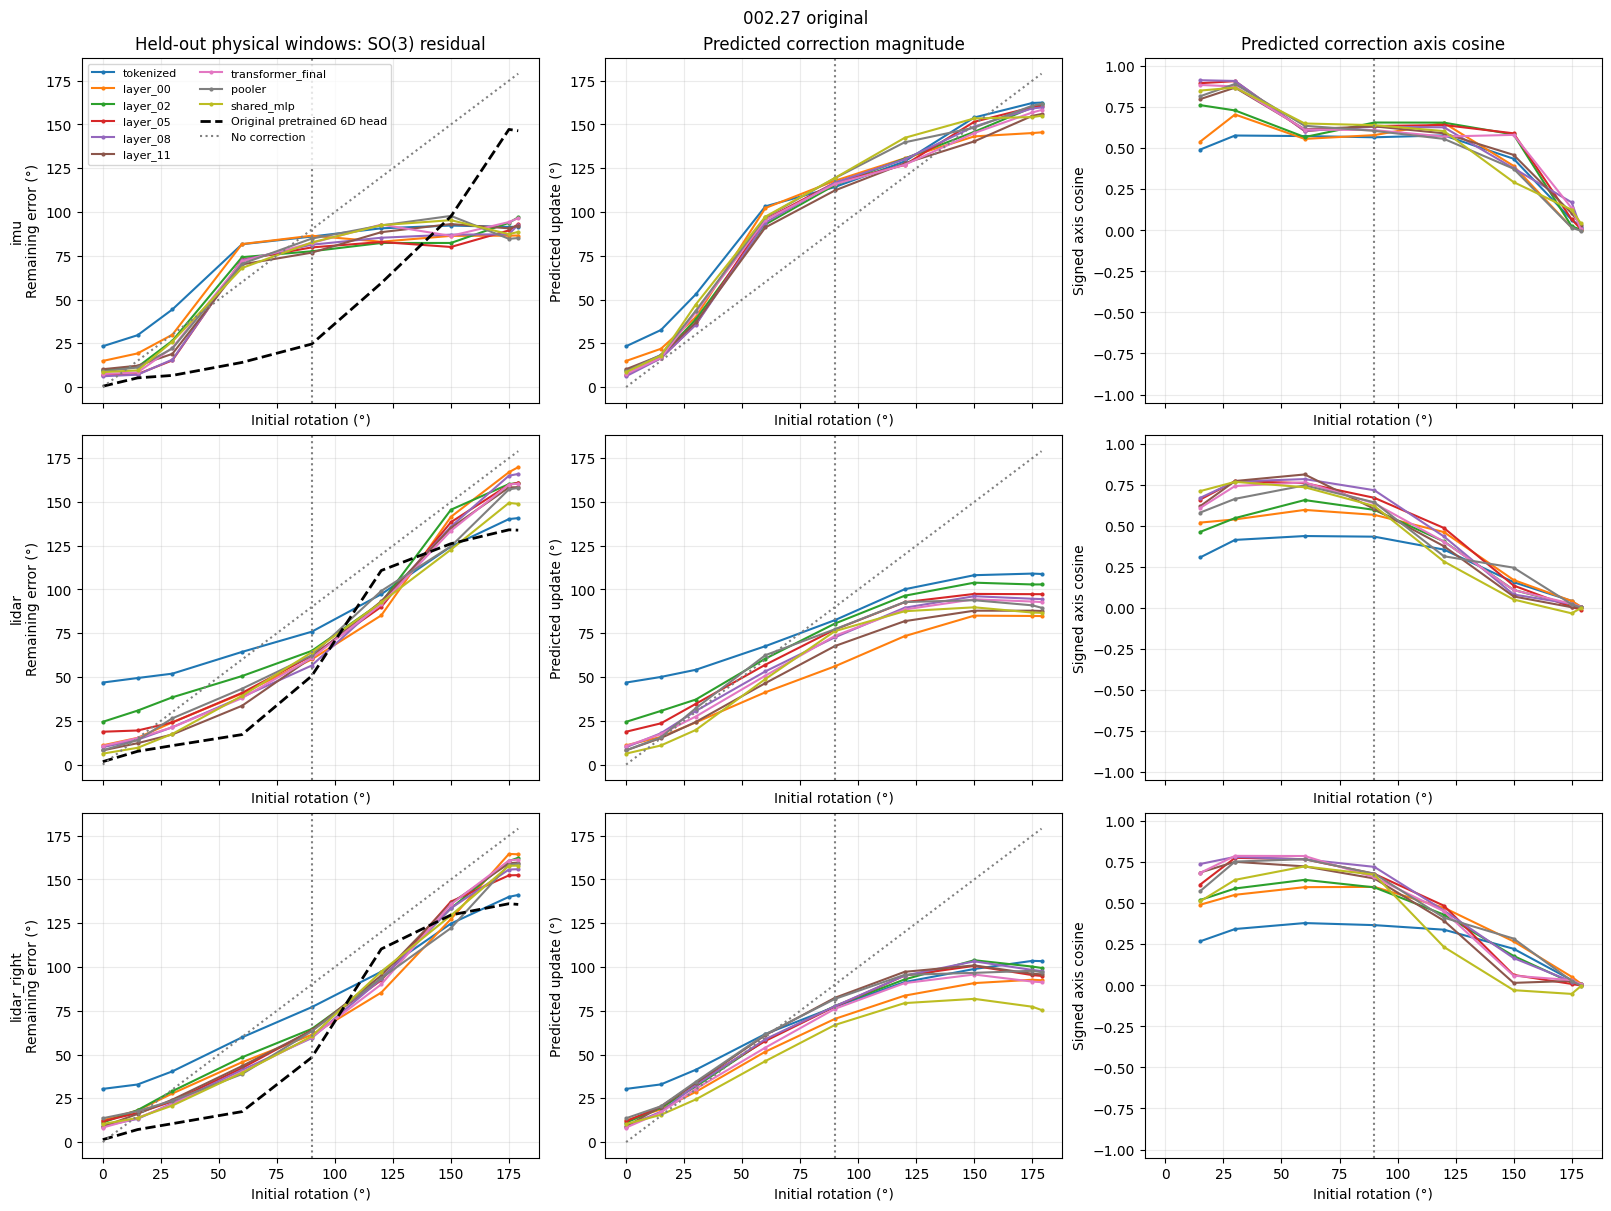

Held-out validation physical windows:


,checkpoint,split,fault_key,level,mean_residual_deg,mean_axis_cos
56,002.27 original,val_new_axes,imu,layer_05,65.070000,0.54
57,002.27 original,val_new_axes,imu,layer_08,66.120003,0.53
58,002.27 original,val_new_axes,imu,layer_11,67.800003,0.51
55,002.27 original,val_new_axes,imu,layer_02,68.139999,0.50
59,002.27 original,val_new_axes,imu,pooler,68.540001,0.49
60,002.27 original,val_new_axes,imu,shared_mlp,68.730003,0.51
62,002.27 original,val_new_axes,imu,transformer_final,69.360001,0.54
54,002.27 original,val_new_axes,imu,layer_00,69.959999,0.43
61,002.27 original,val_new_axes,imu,tokenized,75.940002,0.41
69,002.27 original,val_new_axes,lidar,shared_mlp,80.519997,0.39


In [9]:
if RUN_DECODER_TRAINING_63:
    report_63=(decoder_cases_df_63.groupby(['checkpoint','split','fault_key','level','angle_deg'],as_index=False)
               .agg(after_deg=('decoder_error_deg','mean'),original_deg=('original_head_error_deg','mean'),correction_deg=('decoder_magnitude_deg','mean'),axis_cosine=('axis_cosine','mean'),n=('decoder_error_deg','size')))
    report_63.to_csv(RUN_DIR_63/'decoder_angle_summary.csv',index=False)
    for checkpoint in SELECTED_CHECKPOINTS_63:
        fig,axes=plt.subplots(len(CALIBRATION_KEYS),3,figsize=(16,4*len(CALIBRATION_KEYS)),sharex=True,constrained_layout=True)
        for i,key in enumerate(CALIBRATION_KEYS):
            for level in LEVELS_63:
                part=report_63[(report_63.checkpoint==checkpoint)&(report_63.split=='val_new_axes')&(report_63.fault_key==key)&(report_63.level==level)].sort_values('angle_deg')
                axes[i,0].plot(part.angle_deg,part.after_deg,'-o',ms=2,label=level)
                axes[i,1].plot(part.angle_deg,part.correction_deg,'-o',ms=2,label=level)
                axes[i,2].plot(part.angle_deg,part.axis_cosine,'-o',ms=2,label=level)
            baseline=part.original_deg.values
            angles=part.angle_deg.values
            axes[i,0].plot(angles,baseline,'k--',lw=2,label='Original pretrained 6D head')
            axes[i,0].plot(angles,angles,':',color='gray',label='No correction')
            axes[i,1].plot(angles,angles,':',color='gray',label='GT magnitude')
            for j,ax in enumerate(axes[i]):
                ax.grid(alpha=0.25);ax.axvline(90,ls=':',color='gray')
                ax.set_xlabel('Initial rotation (°)')
                if j==0: ax.set_ylabel(f'{key}\nRemaining error (°)')
                if j==1: ax.set_ylabel('Predicted update (°)')
                if j==2: ax.set_ylabel('Signed axis cosine');ax.set_ylim(-1.05,1.05)
        axes[0,0].set_title('Held-out physical windows: SO(3) residual')
        axes[0,1].set_title('Predicted correction magnitude')
        axes[0,2].set_title('Predicted correction axis cosine')
        axes[0,0].legend(fontsize=8,ncol=2)
        fig.suptitle(checkpoint)
        fig.savefig(RUN_DIR_63/f'decoder_per_angle_{checkpoint.split()[0]}.png',dpi=150)
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)
    overall=(report_63[report_63.angle_deg>0].groupby(['checkpoint','split','fault_key','level'],as_index=False)
            .agg(mean_residual_deg=('after_deg','mean'),mean_axis_cos=('axis_cosine','mean')))
    print('Held-out validation physical windows:')
    display(overall[overall.split=='val_new_axes'].sort_values(['checkpoint','fault_key','mean_residual_deg']).round(2))


## 9. Does the representation **fold** for large signed rotations?

This experiment does not train anything. We hold **one physical window, its true calibration, and one axis** fixed, inject signed angles from −179° through +179°, and record the entire path in each frozen representation. At ±179° the rotations are **2° apart on SO(3)**, so their proximity is expected; folding elsewhere, especially pairs with ~120–180° geodesic separation, would be more concerning.

Metrics:
- 2D PCA visualizes each path without claiming that 2D preserves information.
- A pairwise matrix compares normalized feature distances with exact SO(3) distances along the path.
- The far-rotation collision rate counts pairs whose targets are ≥120° apart but whose *feature distance is unusually small*. Compare this **within a stage**, not across stages with different dimensions.

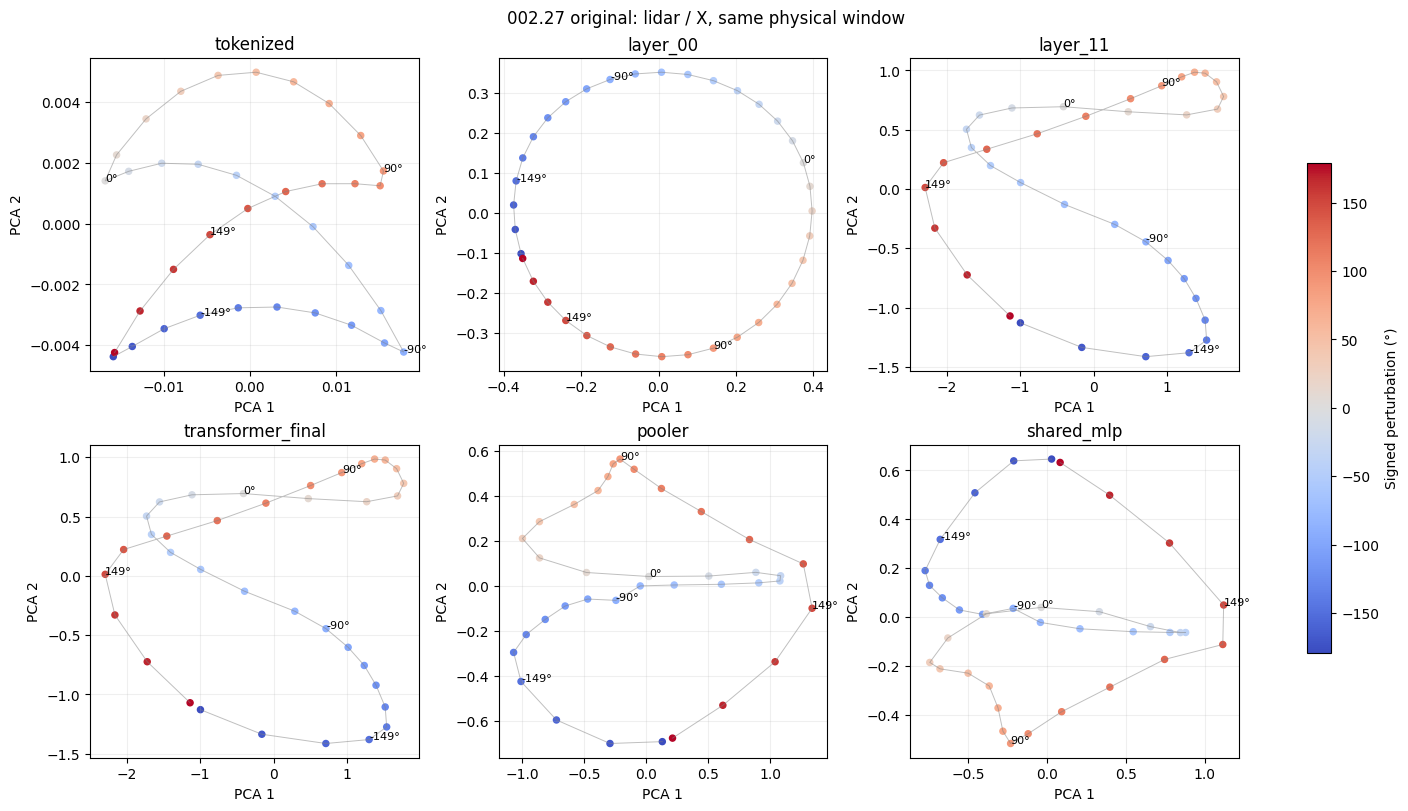

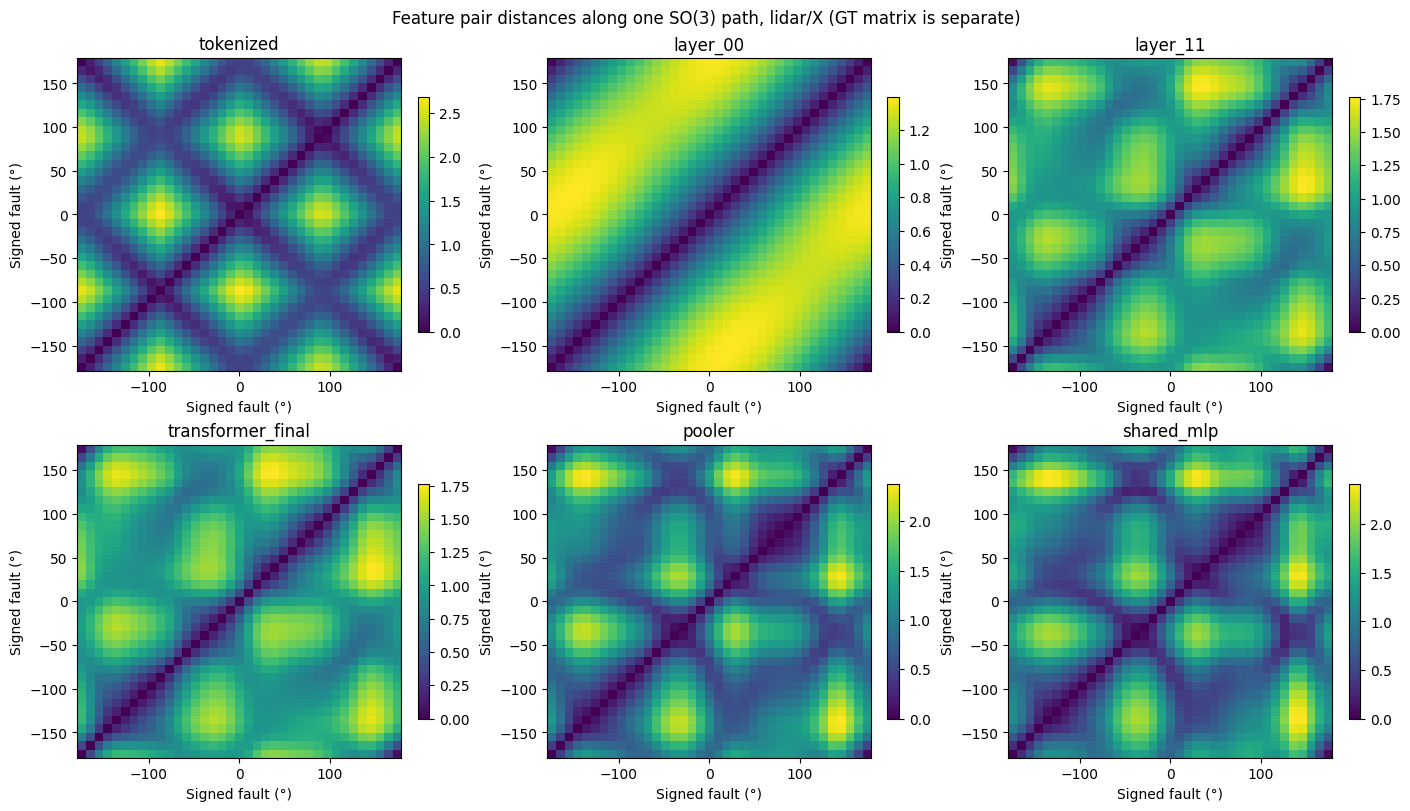

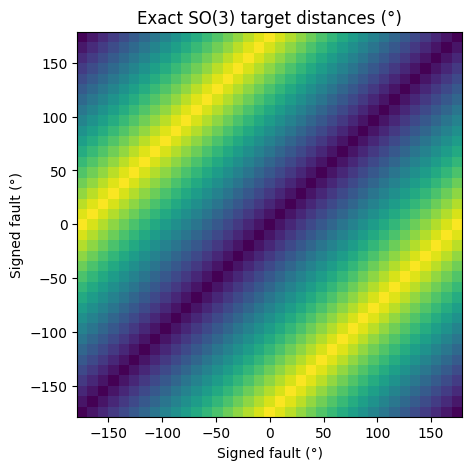

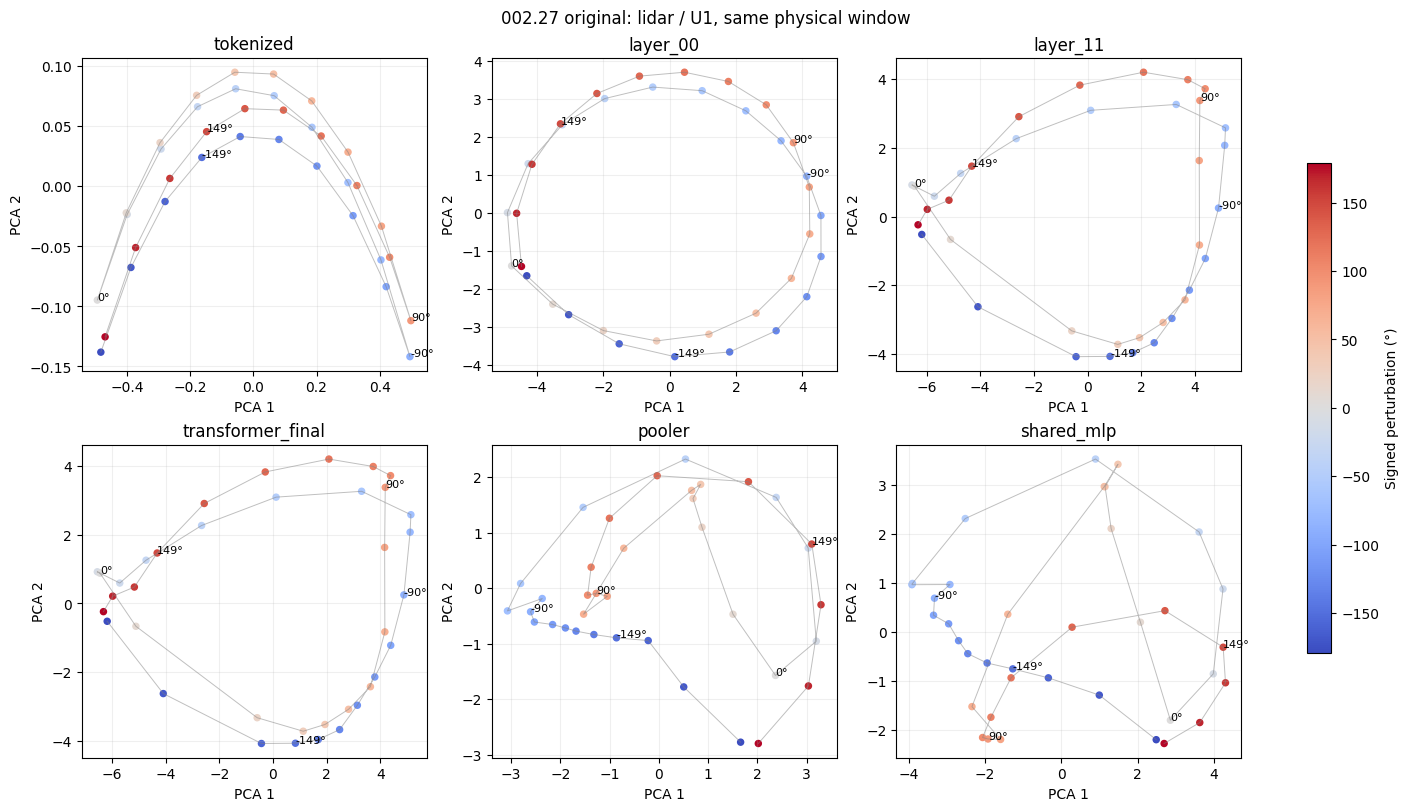

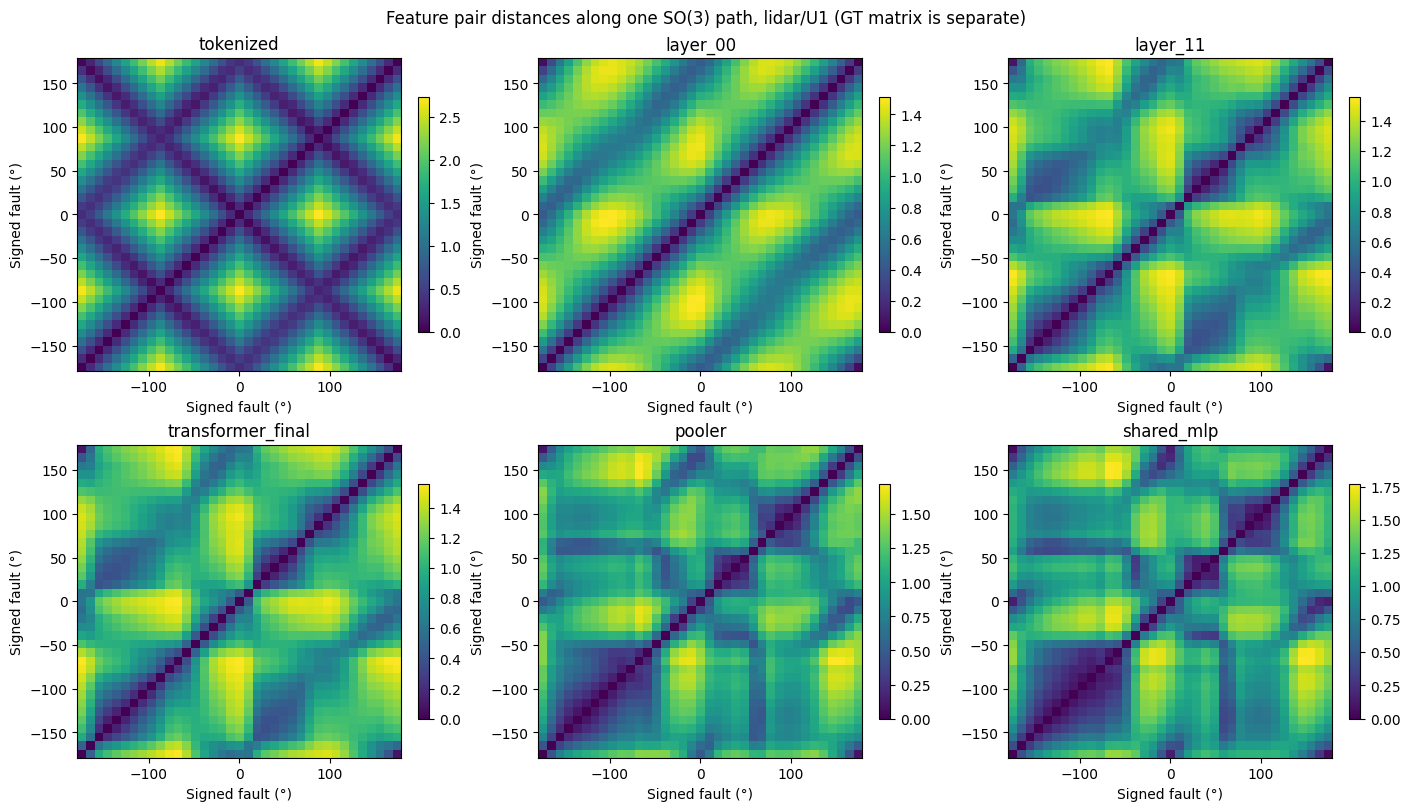

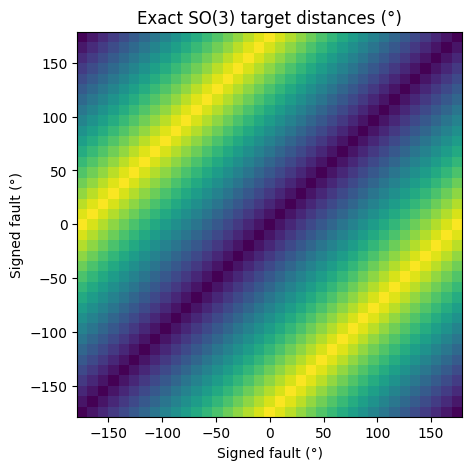

,checkpoint,key,axis,level,far_collision_fraction,spearman_rho
0,002.27 original,lidar,X,tokenized,0.005,0.085
1,002.27 original,lidar,X,layer_00,0.000,0.987
2,002.27 original,lidar,X,layer_11,0.000,0.287
3,002.27 original,lidar,X,transformer_final,0.000,0.287
4,002.27 original,lidar,X,pooler,0.023,0.151
5,002.27 original,lidar,X,shared_mlp,0.050,0.113
6,002.27 original,lidar,U1,tokenized,0.095,0.008
7,002.27 original,lidar,U1,layer_00,0.032,0.092
8,002.27 original,lidar,U1,layer_11,0.068,0.074
9,002.27 original,lidar,U1,transformer_final,0.068,0.074


In [10]:
@torch.inference_mode()
def signed_path_bank_63(model,physical,key,axis,angles):
    records=[];Xs={level:[] for level in LEVELS_63}
    with capture_model_levels_63(model) as captures:
        direction=np.eye(3)['XYZ'.index(axis)] if axis in 'XYZ' and len(axis)==1 else sample_axes_63(1,SEED_63+999)[0]
        for theta in angles:
            prior=perturb_prior_63(physical.current_calibration,key,np.deg2rad(theta),direction)
            window=with_prior_63(physical,prior)
            features=extract_features_63(model,window,captures)
            for level in LEVELS_63:
                Xs[level].append(row_feature_63(features,level,key)[0])
            R=physical.targets[key].next_transform[0,:3,:3] @ prior[key].transform[0,:3,:3].transpose(-1,-2)
            records.append(dict(theta=float(theta),R=R.cpu().numpy().copy()))
    return records,{k:np.stack(v) for k,v in Xs.items()}

def distance_matrix_63(X):
    Y=np.asarray(X,dtype='float64')
    sq=np.sum(Y*Y,axis=1)
    dist=np.sqrt(np.maximum(sq[:,None]+sq[None,:]-2*Y@Y.T,0))
    # Typical distance among distinct samples: makes colormap comparisons useful, not a metric invariant.
    positive=dist[np.triu_indices(len(dist),1)]
    norm=np.median(positive[positive>1e-10]) if np.any(positive>1e-10) else 1.
    return dist/max(norm,1e-10)

def so3_pairwise_63(records):
    R=torch.tensor(np.stack([r['R'] for r in records]),device=DEVICE,dtype=DTYPE)
    pair=rotation_error_deg_63(R[:,None],R[None,:])
    return pair.cpu().numpy()

PATH_ROWS_63=[]
PATH_CACHE_63={}
if RUN_SIGNED_PATH_63:
    frozen=load_frozen_model_63(PATH_CHECKPOINT_63)
    _,physical=train_physical_groups_63[0]
    # Use the same *single* physical window for all path points.
    single_index=int(train_physical_groups_63[0][0][0])
    base=window_batch_to(collate_windows([train_dataset_63[single_index]]),DEVICE,dtype=DTYPE)
    physical=physical_augmenter_63(base,generator=generator_63(SEED_63+1)).augmented_window
    angles=np.linspace(-179.,179.,PATH_NUM_ANGLES_63)
    for axis in PATH_AXES_63:
        records,Xs=signed_path_bank_63(frozen,physical,PATH_FAULT_KEY_63,axis,angles)
        gt=so3_pairwise_63(records)
        PATH_CACHE_63[axis]=(angles.copy(),Xs,gt)
        fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
        show_levels=['tokenized',f'layer_{CAPTURE_LAYERS_63[0]:02d}',f'layer_{CAPTURE_LAYERS_63[-1]:02d}','transformer_final','pooler','shared_mlp']
        for ax,level in zip(axes.flat,show_levels):
            X=Xs[level].astype('float64');X=X-X.mean(axis=0,keepdims=True)
            U,s,V=np.linalg.svd(X,full_matrices=False)
            coords=U[:,:2]*s[:2]
            ax.plot(coords[:,0],coords[:,1],'-',lw=0.7,alpha=0.5,color='gray')
            sc=ax.scatter(coords[:,0],coords[:,1],c=angles,cmap='coolwarm',vmin=-179,vmax=179,s=19)
            for desired in (-150,-90,0,90,150):
                pos=int(np.argmin(abs(angles-desired)))
                ax.annotate(f'{angles[pos]:.0f}°',coords[pos],fontsize=8)
            ax.set(title=level,xlabel='PCA 1',ylabel='PCA 2');ax.grid(alpha=.2)
        fig.colorbar(sc,ax=axes.ravel().tolist(),label='Signed perturbation (°)',shrink=.7)
        fig.suptitle(f'{PATH_CHECKPOINT_63}: {PATH_FAULT_KEY_63} / {axis}, same physical window')
        fig.savefig(RUN_DIR_63/f'path_pca_{PATH_FAULT_KEY_63}_{axis}.png',dpi=150)
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)
        fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
        for ax,level in zip(axes.flat,show_levels):
            D=distance_matrix_63(Xs[level]);im=ax.imshow(D,origin='lower',extent=[angles[0],angles[-1],angles[0],angles[-1]],cmap='viridis',aspect='auto')
            ax.set(title=level,xlabel='Signed fault (°)',ylabel='Signed fault (°)')
            fig.colorbar(im,ax=ax,shrink=.75)
            ii,jj=np.triu_indices(len(angles),1)
            far=gt[ii,jj]>=120.
            allD=D[ii,jj]
            threshold=np.quantile(allD,.1)
            collision_fraction=float(np.mean(allD[far]<=threshold)) if far.any() else float('nan')
            rho=float(pd.Series(gt[ii,jj]).corr(pd.Series(allD),method='spearman'))
            PATH_ROWS_63.append(dict(checkpoint=PATH_CHECKPOINT_63,key=PATH_FAULT_KEY_63,axis=axis,level=level,far_collision_fraction=collision_fraction,spearman_rho=rho))
        fig.suptitle(f'Feature pair distances along one SO(3) path, {PATH_FAULT_KEY_63}/{axis} (GT matrix is separate)')
        fig.savefig(RUN_DIR_63/f'path_pairwise_{PATH_FAULT_KEY_63}_{axis}.png',dpi=150)
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)
        fig,ax=plt.subplots(1,1,figsize=(6,5))
        ax.imshow(gt,origin='lower',extent=[angles[0],angles[-1],angles[0],angles[-1]],cmap='viridis',vmin=0,vmax=180)
        ax.set(title='Exact SO(3) target distances (°)',xlabel='Signed fault (°)',ylabel='Signed fault (°)')
        fig.savefig(RUN_DIR_63/f'path_ground_truth_{PATH_FAULT_KEY_63}_{axis}.png',dpi=150)
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)
    path_summary_63=pd.DataFrame(PATH_ROWS_63)
    path_summary_63.to_csv(RUN_DIR_63/'signed_path_geometry.csv',index=False)
    display(path_summary_63.round(3))
    del frozen


### 9B. Does the representation compress or fold above 90°?

Plot the *local sensitivity* of frozen features as an angle varies by roughly 10°, normalized to the 20–60° region, plus distances between +θ and −θ. These pairs are maximally separated on SO(3) around θ=90° but properly become similar near θ=180°. A consistent collapse in local sensitivity across late levels but not early levels would support the representation-compression hypothesis. The test holds the same physical window and axis fixed.

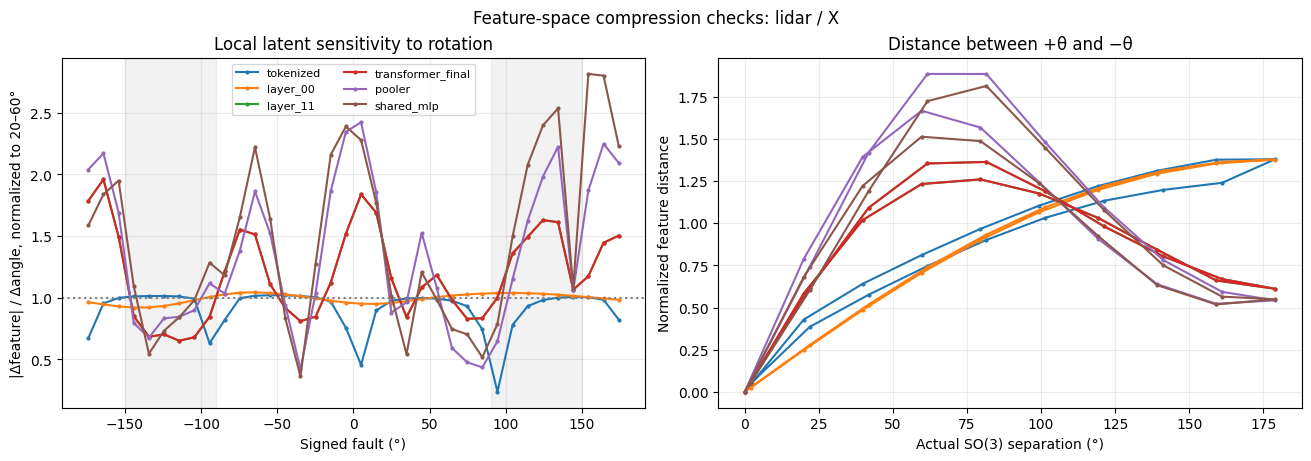

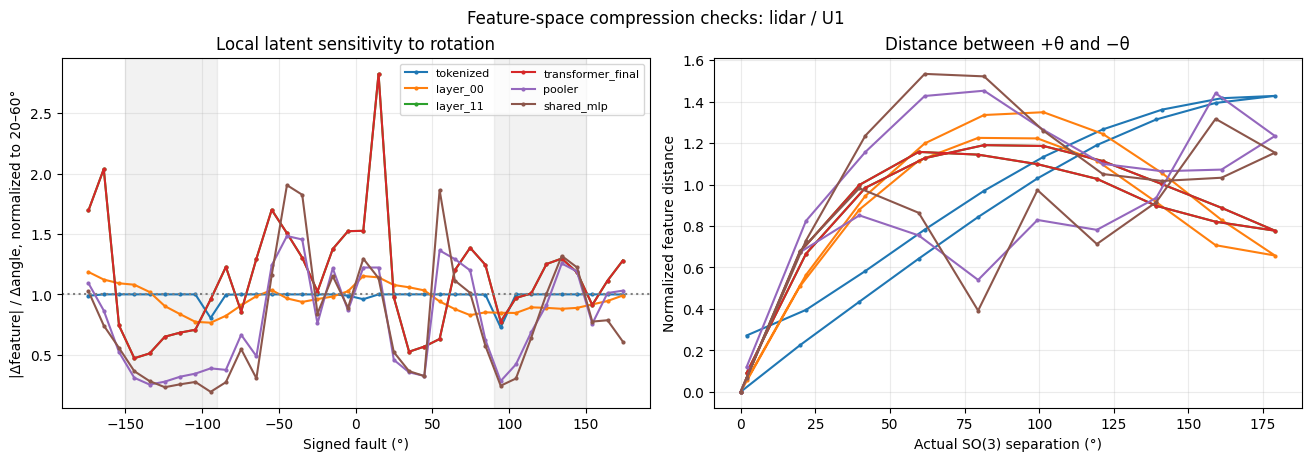

In [11]:
# Additional targeted test of latent compression near and above 90 degrees.
# Requires the signed-path cell to have populated PATH_CACHE_63.
if RUN_SIGNED_PATH_63:
    for axis, (thetas, Xs, gt) in PATH_CACHE_63.items():
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
        level_names = ['tokenized', f'layer_{CAPTURE_LAYERS_63[0]:02d}', f'layer_{CAPTURE_LAYERS_63[-1]:02d}', 'transformer_final', 'pooler', 'shared_mlp']
        centers = (thetas[:-1] + thetas[1:]) / 2
        positive = thetas[thetas >= 0]
        for level in level_names:
            X = Xs[level].astype('float64')
            local_speed = np.linalg.norm(np.diff(X, axis=0), axis=1) / np.diff(thetas)
            anchor = np.median(local_speed[(np.abs(centers) >= 20) & (np.abs(centers) <= 60)])
            normalized_speed = local_speed / max(anchor, 1e-12)
            axes[0].plot(centers, normalized_speed, '-o', ms=2, label=level)
            unsigned, gt_unsigned = [], []
            for t in positive:
                neg_i = int(np.argmin(abs(thetas + t)))
                pos_i = int(np.argmin(abs(thetas - t)))
                unsigned.append(np.linalg.norm(X[pos_i] - X[neg_i]))
                gt_unsigned.append(gt[pos_i, neg_i])
            unsigned = np.array(unsigned)
            norm = np.median(unsigned[np.isfinite(unsigned) & (unsigned > 1e-10)]) if np.any(unsigned > 1e-10) else 1.
            axes[1].plot(gt_unsigned, unsigned / max(norm, 1e-12), '-o', ms=2, label=level)
        axes[0].axvspan(-150, -90, color='gray', alpha=.1)
        axes[0].axvspan(90, 150, color='gray', alpha=.1)
        axes[0].axhline(1, ls=':', color='gray')
        axes[0].set(title='Local latent sensitivity to rotation', xlabel='Signed fault (°)', ylabel='|Δfeature| / Δangle, normalized to 20–60°')
        axes[1].set(title='Distance between +θ and −θ', xlabel='Actual SO(3) separation (°)', ylabel='Normalized feature distance')
        for ax in axes:
            ax.grid(alpha=.25)
        axes[0].legend(fontsize=8, ncol=2)
        fig.suptitle(f'Feature-space compression checks: {PATH_FAULT_KEY_63} / {axis}')
        fig.savefig(RUN_DIR_63 / f'path_sensitivity_{PATH_FAULT_KEY_63}_{axis}.png', dpi=150)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)


## 10. Interpretation and next experiment

| What happens | What it means | Strongest follow-up |
|---|---|---|
| New decoder works at final pooling/MLP on **held-out axes and windows**, but original 6D head does not | Useful information survives; original head training/optimization is suspect | Retrain head with frozen backbone; test per-key heads and loss alternatives |
| Early Transformer levels decode well but late stages fail, especially beyond 90° | Evidence of a learned representation bottleneck | Keep early layers; test late-layer bypass, skip connection, or multi-scale pooling |
| Final Transformer works but pooler and shared MLP fail | The calibration pooler/MLP is losing information | Multi-token pooling or direct cross-attention readout, before increasing depth |
| Decoders fit training cases but fail on **new axes on same physical windows** | Rotation-axis generalization is poor | Test SO(3)-equivariant features / relative vector geometry before scale-up |
| Same-window heldout axes succeed, unseen physical windows fail | Dependence on motion/excitation, true frame, or sequence-level generalization | More physical-window diversity, motion-conditioned confidence / observability tests |
| Even early features and the new decoders cannot fit training cases | Inconclusive about input information: fixed temporal moments may discard it | Train a probe with attention over **full frozen token sequences** or inspect exact sensor alignment |
| Signed-path embeddings visibly fold while GT pairs remain far apart | Direct evidence of representation aliasing on the tested physical window | Test rotation-equivariant or rotation-aware encoder with matched comparison |

**About the 90° boundary:** neither SO(3) nor 6D rotations have a fundamental singularity at 90°. A compression/folding diagnostic can reveal a learned effective boundary, but cannot by itself establish why it arose. Near ±179°, valid SO(3) rotations are close to each other; never count that as a collision.

**About SO(3)-aware encoding:** a promising next controlled architecture is a vector-feature encoder with scalar invariants (dot products, norms) and equivariant vector channels that transform consistently when the calibration prior changes. Unlike a larger ordinary Transformer, this changes the *inductive bias* so the network can represent and compare rotated sensor vectors across arbitrary axes. First use this notebook to identify the stage at which geometric information stops being decodable.

## Appendix 11. Does the encoder confuse opposite hemispheres?
Controlled diagnostic for the hypothesis that the learned feature behaves like sin(theta) * axis, which makes rotations of theta and 180-theta indistinguishable. Reuses Notebook 63 augmentation, hooks, and full 6D head. No network training. The first appendix cell uses validation physical windows only.

In [12]:
# Notebook 63, appendix A: angle-mirror hypothesis, frozen-model diagnostic.
# Requires the existing Notebook 63 definitions through row_feature_63 / sample_axes_63.
HEMI63_CHECKPOINTS = ('002.27 original',)  # Add '002.30 single-axis' for a paired checkpoint comparison.
HEMI63_KEYS = ('lidar', 'lidar_right', 'imu')
HEMI63_AXES = {'X': np.array([1., 0., 0.]), 'U1': sample_axes_63(1, SEED_63 + 999)[0]}
HEMI63_ANGLES = (0., 15., 30., 45., 60., 75., 90., 105., 120., 135., 150., 165., 179.)
HEMI63_MIRROR_LOW = (15., 30., 45., 60., 75.)
HEMI63_PHYSICAL_GROUPS = 2  # Each group normally contains four unseen physical windows.
HEMI63_LEVELS = ('tokenized', 'layer_00', 'layer_05', 'layer_11', 'pooler', 'shared_mlp')
HEMI63_OUT = RUN_DIR_63 / 'hemisphere_aliasing'
HEMI63_OUT.mkdir(parents=True, exist_ok=True)

for name in HEMI63_CHECKPOINTS:
    if not CHECKPOINTS_63[name].is_file():
        raise FileNotFoundError(CHECKPOINTS_63[name])
for name in HEMI63_LEVELS:
    if name not in LEVELS_63:
        raise ValueError(f'Missing extracted feature level: {name}; available: {LEVELS_63}')

HEMI63_ROWS = []
HEMI63_FEATURES = {}

with torch.inference_mode():
    for checkpoint in HEMI63_CHECKPOINTS:
        frozen = load_frozen_model_63(checkpoint)
        for group_index, (dataset_indices, physical) in enumerate(val_physical_groups_63[:HEMI63_PHYSICAL_GROUPS]):
            # Keep sensor streams, true calibration, and randomized physical frames IDENTICAL for all angles.
            batch_size = len(dataset_indices)
            for key in HEMI63_KEYS:
                for axis_name, axis in HEMI63_AXES.items():
                    with capture_model_levels_63(frozen) as captures:
                        for angle in HEMI63_ANGLES:
                            prior = perturb_prior_63(physical.current_calibration, key, np.deg2rad(angle), axis)
                            window = with_prior_63(physical, prior)
                            features = extract_features_63(frozen, window, captures)
                            true_R = physical.targets[key].next_transform[:, :3, :3] @ prior[key].transform[:, :3, :3].transpose(-1, -2)
                            pred_R = rotation_6d_to_matrix(torch.as_tensor(features[f'original_6d/{key}'], device=DEVICE, dtype=DTYPE))
                            eye_R = torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(pred_R)
                            actual_deg = rotation_error_deg_63(true_R, eye_R).cpu().numpy()
                            if not np.allclose(actual_deg, angle, atol=0.1):
                                raise AssertionError(f'Correction convention differs from requested angle: {key} {angle}, got {actual_deg}')
                            pred_deg = rotation_error_deg_63(pred_R, eye_R).cpu().numpy()
                            error_deg = rotation_error_deg_63(pred_R, true_R).cpu().numpy()
                            axis_cos = rotation_axis_cosine_63(pred_R, true_R).cpu().numpy()
                            for level in HEMI63_LEVELS:
                                HEMI63_FEATURES[(checkpoint, group_index, key, axis_name, float(angle), level)] = np.asarray(row_feature_63(features, level, key), dtype=np.float64).copy()
                            for j, physical_index in enumerate(dataset_indices):
                                HEMI63_ROWS.append(dict(checkpoint=checkpoint, group_index=group_index, physical_index=int(physical_index), sample_index=j, key=key, axis=axis_name, angle_deg=angle, predicted_deg=float(pred_deg[j]), residual_deg=float(error_deg[j]), axis_cosine=float(axis_cos[j])))
                    print(f'{checkpoint} | val group {group_index + 1} | {key} {axis_name}: extracted {len(HEMI63_ANGLES)} angles', flush=True)
        del frozen
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

hemi_cases_63 = pd.DataFrame(HEMI63_ROWS)
hemi_cases_63.to_csv(HEMI63_OUT / 'predictions_per_case.csv', index=False)
print('Cases:', len(hemi_cases_63), '| physical windows:', hemi_cases_63.physical_index.nunique())


002.27 original | val group 1 | lidar X: extracted 13 angles
002.27 original | val group 1 | lidar U1: extracted 13 angles
002.27 original | val group 1 | lidar_right X: extracted 13 angles
002.27 original | val group 1 | lidar_right U1: extracted 13 angles
002.27 original | val group 1 | imu X: extracted 13 angles
002.27 original | val group 1 | imu U1: extracted 13 angles
002.27 original | val group 2 | lidar X: extracted 13 angles
002.27 original | val group 2 | lidar U1: extracted 13 angles
002.27 original | val group 2 | lidar_right X: extracted 13 angles
002.27 original | val group 2 | lidar_right U1: extracted 13 angles
002.27 original | val group 2 | imu X: extracted 13 angles
002.27 original | val group 2 | imu U1: extracted 13 angles
Cases: 624 | physical windows: 8


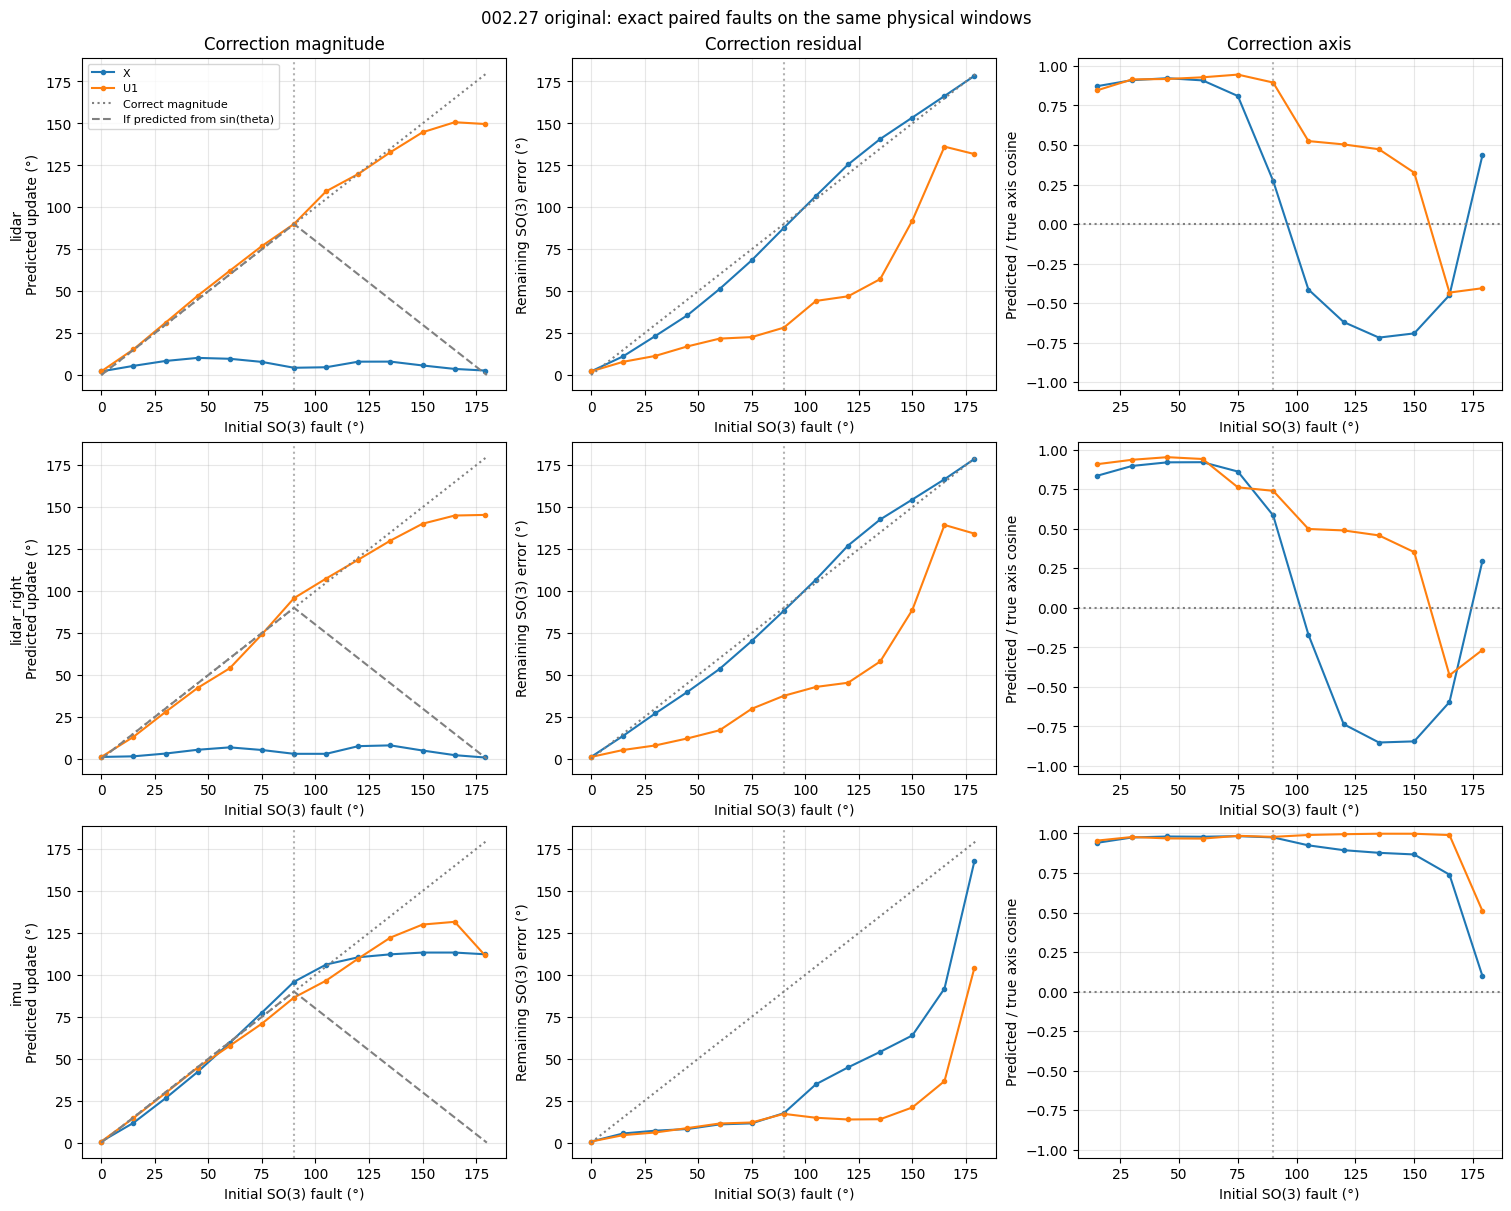

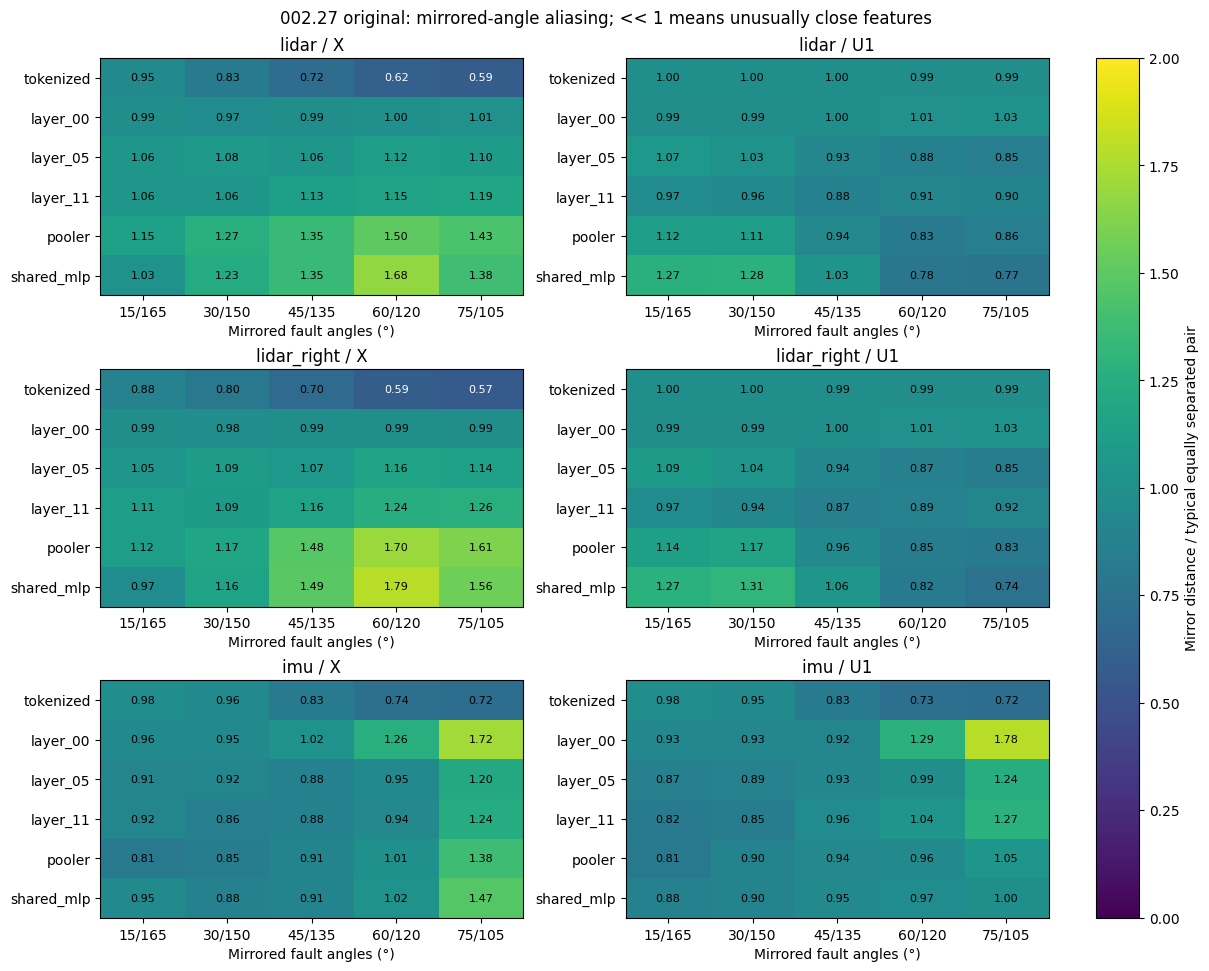

Median ratio by checkpoint/key/feature level (below 0.25 is strong aliasing evidence):


,checkpoint,key,level,distance_ratio
0,002.27 original,imu,layer_00,0.962
1,002.27 original,imu,layer_05,0.922
2,002.27 original,imu,layer_11,0.934
3,002.27 original,imu,pooler,0.907
4,002.27 original,imu,shared_mlp,0.928
5,002.27 original,imu,tokenized,0.834
6,002.27 original,lidar,layer_00,0.993
7,002.27 original,lidar,layer_05,1.041
8,002.27 original,lidar,layer_11,0.987
9,002.27 original,lidar,pooler,1.138


In [13]:
# Notebook 63, appendix B: distinguish sin(theta) aliasing from correction underestimation.
hemi_means_63 = (hemi_cases_63.groupby(['checkpoint', 'key', 'axis', 'angle_deg'], as_index=False)
                 .agg(predicted_deg=('predicted_deg', 'mean'), residual_deg=('residual_deg', 'mean'), axis_cosine=('axis_cosine', 'mean')))

for checkpoint in HEMI63_CHECKPOINTS:
    fig, axes = plt.subplots(len(HEMI63_KEYS), 3, figsize=(15, 4 * len(HEMI63_KEYS)), squeeze=False, constrained_layout=True)
    for row, key in enumerate(HEMI63_KEYS):
        for axis_name in HEMI63_AXES:
            part = hemi_means_63[(hemi_means_63.checkpoint == checkpoint) & (hemi_means_63.key == key) & (hemi_means_63.axis == axis_name)].sort_values('angle_deg')
            a = part.angle_deg.to_numpy()
            axes[row, 0].plot(a, part.predicted_deg, '-o', ms=3, label=axis_name)
            axes[row, 1].plot(a, part.residual_deg, '-o', ms=3, label=axis_name)
            axes[row, 2].plot(a, part.axis_cosine, '-o', ms=3, label=axis_name)
        a = np.linspace(0, 180, 361)
        axes[row, 0].plot(a, a, ':', color='gray', label='Correct magnitude')
        axes[row, 0].plot(a, np.rad2deg(np.arcsin(np.sin(np.deg2rad(a)))), '--', color='gray', label='If predicted from sin(theta)')
        axes[row, 1].plot(a, a, ':', color='gray', label='No correction')
        axes[row, 2].axhline(0, ls=':', color='gray')
        for ax in axes[row]:
            ax.axvline(90, ls=':', color='gray', alpha=.6)
            ax.grid(alpha=.3)
            ax.set_xlabel('Initial SO(3) fault (°)')
        axes[row, 0].set_ylabel(f'{key}\nPredicted update (°)')
        axes[row, 1].set_ylabel('Remaining SO(3) error (°)')
        axes[row, 2].set_ylabel('Predicted / true axis cosine')
        axes[row, 2].set_ylim(-1.05, 1.05)
    for col, title in enumerate(('Correction magnitude', 'Correction residual', 'Correction axis')):
        axes[0, col].set_title(title)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{checkpoint}: exact paired faults on the same physical windows')
    fig.savefig(HEMI63_OUT / f'head_mirror_{checkpoint.split()[0]}.png', dpi=150)
    plt.show()

# Exact SO(3) separation for R(theta,u) vs R(180-theta,u) is 180-2*theta degrees.
# Compare their feature distance to OTHER angle pairs having the SAME SO(3) separation.
# This controls for feature scaling and avoids mistaking generally small distances for folding.
mirror_rows_63 = []
for (checkpoint, group_index, key, axis_name, angle, level), unused in HEMI63_FEATURES.items():
    if angle != 0.:  # Each physical group / level is processed once.
        continue
    Z = {t: HEMI63_FEATURES[(checkpoint, group_index, key, axis_name, t, level)] for t in HEMI63_ANGLES}
    for small in HEMI63_MIRROR_LOW:
        large = 180. - small
        separation = large - small
        mirror_distance = np.linalg.norm(Z[small] - Z[large], axis=-1)
        control_distances = []
        for i, t1 in enumerate(HEMI63_ANGLES):
            for t2 in HEMI63_ANGLES[i + 1:]:
                if abs((t2 - t1) - separation) < 1e-6 and (t1, t2) != (small, large):
                    control_distances.append(np.linalg.norm(Z[t1] - Z[t2], axis=-1))
        if not control_distances:
            raise RuntimeError(f'No same-separation control pairs for {small} / {large}')
        control = np.median(np.stack(control_distances), axis=0)
        ratio = mirror_distance / np.maximum(control, 1e-12)
        for j, value in enumerate(ratio):
            mirror_rows_63.append(dict(checkpoint=checkpoint, group_index=group_index, physical_index=int(val_physical_groups_63[group_index][0][j]), key=key, axis=axis_name, level=level, lower_angle=small, upper_angle=large, target_separation=separation, mirror_distance=float(mirror_distance[j]), control_distance=float(control[j]), distance_ratio=float(value)))
mirror_df_63 = pd.DataFrame(mirror_rows_63)
mirror_df_63.to_csv(HEMI63_OUT / 'mirror_feature_distance_ratios.csv', index=False)

for checkpoint in HEMI63_CHECKPOINTS:
    fig, axes = plt.subplots(len(HEMI63_KEYS), len(HEMI63_AXES), figsize=(12, 3.2 * len(HEMI63_KEYS)), squeeze=False, constrained_layout=True)
    for i, key in enumerate(HEMI63_KEYS):
        for j, axis_name in enumerate(HEMI63_AXES):
            table = mirror_df_63[(mirror_df_63.checkpoint == checkpoint) & (mirror_df_63.key == key) & (mirror_df_63.axis == axis_name)]
            matrix = table.pivot_table(index='level', columns='lower_angle', values='distance_ratio', aggfunc='median').reindex(index=HEMI63_LEVELS, columns=HEMI63_MIRROR_LOW)
            im = axes[i, j].imshow(matrix.to_numpy(), aspect='auto', vmin=0, vmax=2, cmap='viridis')
            axes[i, j].set_xticks(range(len(matrix.columns)), labels=[f'{int(t)}/{int(180 - t)}' for t in matrix.columns])
            axes[i, j].set_yticks(range(len(matrix.index)), labels=matrix.index)
            axes[i, j].set_title(f'{key} / {axis_name}')
            axes[i, j].set_xlabel('Mirrored fault angles (°)')
            for (ri, ci), value in np.ndenumerate(matrix.to_numpy()):
                axes[i, j].text(ci, ri, f'{value:.2f}', ha='center', va='center', fontsize=8, color='white' if value < 0.7 else 'black')
    fig.colorbar(im, ax=axes.ravel().tolist(), label='Mirror distance / typical equally separated pair')
    fig.suptitle(f'{checkpoint}: mirrored-angle aliasing; << 1 means unusually close features')
    fig.savefig(HEMI63_OUT / f'mirror_feature_ratios_{checkpoint.split()[0]}.png', dpi=150)
    plt.show()

print('Median ratio by checkpoint/key/feature level (below 0.25 is strong aliasing evidence):')
display(mirror_df_63.groupby(['checkpoint', 'key', 'level'], as_index=False).distance_ratio.median().round(3))


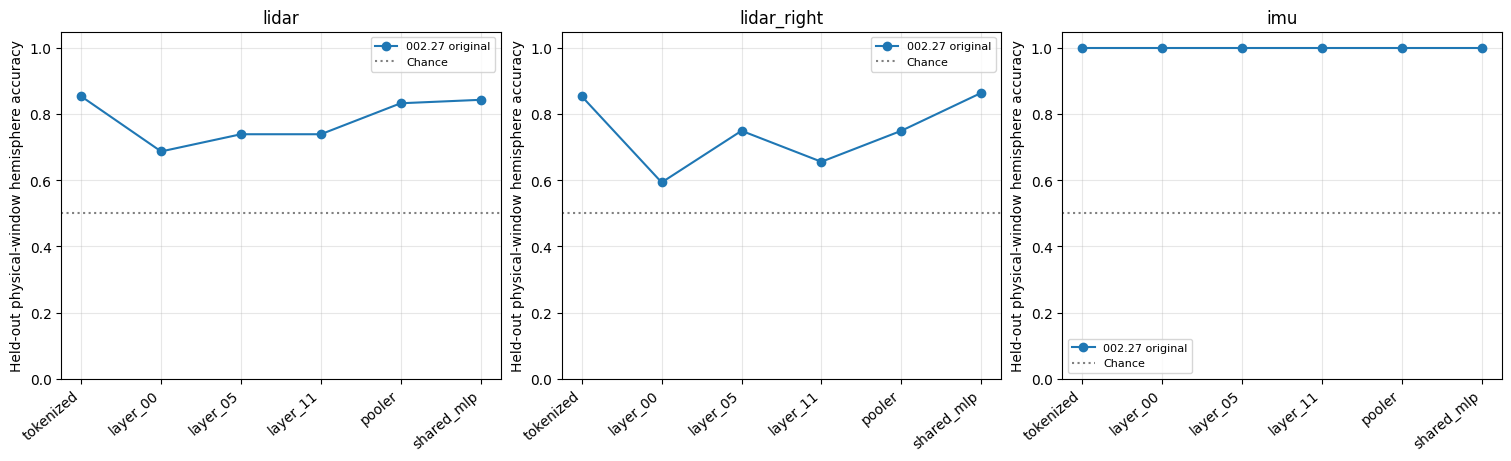

,checkpoint,key,level,split,hemisphere_accuracy,cosine_mae,n_cases
1,002.27 original,lidar,tokenized,heldout_physical,0.854,0.663,96
3,002.27 original,lidar,layer_00,heldout_physical,0.688,0.512,96
5,002.27 original,lidar,layer_05,heldout_physical,0.740,0.604,96
7,002.27 original,lidar,layer_11,heldout_physical,0.740,0.655,96
9,002.27 original,lidar,pooler,heldout_physical,0.833,0.485,96
11,002.27 original,lidar,shared_mlp,heldout_physical,0.844,0.415,96
13,002.27 original,lidar_right,tokenized,heldout_physical,0.854,0.825,96
15,002.27 original,lidar_right,layer_00,heldout_physical,0.594,0.738,96
17,002.27 original,lidar_right,layer_05,heldout_physical,0.750,0.547,96
19,002.27 original,lidar_right,layer_11,heldout_physical,0.656,0.707,96


In [14]:
# Notebook 63, appendix C: can a tiny linear readout recover the MISSING cosine hemisphere cue?
# It is a diagnostic oracle label, not an inference-time input. Group 0 is the probe's training set,
# the other group(s) are independent physical windows; the frozen encoder never trains.
if HEMI63_PHYSICAL_GROUPS < 2:
    print('Linear hemisphere probe skipped: set HEMI63_PHYSICAL_GROUPS >= 2 and rerun appendix A.')
else:
    hemi_linear_rows_63 = []
    for checkpoint in HEMI63_CHECKPOINTS:
        for key in HEMI63_KEYS:
            for level in HEMI63_LEVELS:
                for split, groups in [('train', [0]), ('heldout_physical', list(range(1, HEMI63_PHYSICAL_GROUPS)))]:
                    feature_items, targets = [], []
                    for group_id in groups:
                        for axis_name in HEMI63_AXES:
                            for angle in HEMI63_ANGLES:
                                if angle == 90.:  # Hemisphere is undefined exactly on the boundary.
                                    continue
                                z = HEMI63_FEATURES[(checkpoint, group_id, key, axis_name, angle, level)]
                                feature_items.append(z)
                                targets.append(np.full(len(z), np.cos(np.deg2rad(angle))))
                    X = np.concatenate(feature_items).astype(np.float64)
                    y = np.concatenate(targets)
                    if split == 'train':
                        mean, scale = X.mean(axis=0), np.maximum(X.std(axis=0), 1e-3)
                        Xtrain = np.clip((X - mean) / scale, -15, 15)
                        ymean = y.mean()
                        # Dual ridge is efficient when there are many feature dimensions.
                        alpha = 25.0
                        weights = np.linalg.solve(Xtrain @ Xtrain.T + alpha * np.eye(len(Xtrain)), y - ymean)
                        w = Xtrain.T @ weights
                    prediction = (np.clip((X - mean) / scale, -15, 15) @ w) + ymean
                    accuracy = float(np.mean((prediction > 0) == (y > 0)))
                    mae = float(np.mean(np.abs(prediction - y)))
                    hemi_linear_rows_63.append(dict(checkpoint=checkpoint, key=key, level=level, split=split, hemisphere_accuracy=accuracy, cosine_mae=mae, n_cases=len(y)))
    hemisphere_probe_df_63 = pd.DataFrame(hemi_linear_rows_63)
    hemisphere_probe_df_63.to_csv(HEMI63_OUT / 'linear_cosine_hemisphere_probe.csv', index=False)
    fig, axes = plt.subplots(1, len(HEMI63_KEYS), figsize=(5 * len(HEMI63_KEYS), 4.5), squeeze=False, constrained_layout=True)
    for i, key in enumerate(HEMI63_KEYS):
        ax = axes[0, i]
        for checkpoint in HEMI63_CHECKPOINTS:
            part = hemisphere_probe_df_63[(hemisphere_probe_df_63.checkpoint == checkpoint) & (hemisphere_probe_df_63.key == key) & (hemisphere_probe_df_63.split == 'heldout_physical')].set_index('level').reindex(HEMI63_LEVELS)
            ax.plot(range(len(part)), part.hemisphere_accuracy, '-o', label=checkpoint)
        ax.axhline(0.5, ls=':', color='gray', label='Chance')
        ax.set_xticks(range(len(HEMI63_LEVELS)), labels=HEMI63_LEVELS, rotation=40, ha='right')
        ax.set_ylim(0, 1.05)
        ax.set_title(key)
        ax.set_ylabel('Held-out physical-window hemisphere accuracy')
        ax.grid(alpha=.3)
        ax.legend(fontsize=8)
    fig.savefig(HEMI63_OUT / 'cosine_hemisphere_decode.png', dpi=150)
    plt.show()
    display(hemisphere_probe_df_63[hemisphere_probe_df_63.split == 'heldout_physical'].round(3))
